<a href="https://colab.research.google.com/github/dbonjd007/ds-core-projects/blob/main/xgboost-models/India-Rent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("pranavshinde36/india-house-rent-prediction")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'india-house-rent-prediction' dataset.
Path to dataset files: /kaggle/input/india-house-rent-prediction


In [ ]:
# Feature Engineering
df = df.sort_values(by=['city', 'rent'])

df['Lag_1_Rent'] = df.groupby('city')['rent'].shift(1)
df = df.dropna()
df.head()

,house_type,locality,city,area,beds,bathrooms,balconies,furnishing,area_rate,rent,Lag_1_Rent
4440,1 BHK House for Rent in Ramamurthy Nagar Banga...,Ramamurthy Nagar,Bangalore,400.0,1,1,0,Furnished,10.0,4000.0,3500.0
1919,1 BHK House for Rent in Hennur Main Road Banga...,Hennur Main Road,Bangalore,100.0,1,1,0,Unfurnished,45.0,4500.0,4000.0
1998,1 BHK House for Rent in Chamrajpet Bangalore,Chamrajpet,Bangalore,150.0,1,1,0,Unfurnished,30.0,4500.0,4500.0
2399,"1 BHK House for Rent in Kammagondahalli, Jalah...",Kammagondahalli,Bangalore,400.0,1,1,0,Unfurnished,11.0,4500.0,4500.0
2803,1 BHK House for Rent in Anchepalya Bangalore,Anchepalya,Bangalore,400.0,1,1,0,Unfurnished,11.0,4500.0,4500.0


In [ ]:
#Define Features

# Correcting data leakage: 'rent' should not be a feature when it's also the target.
# Also including the engineered 'Lag_1_Rent' feature.
features = ['area', 'beds', 'bathrooms',
       'balconies', 'area_rate', 'Lag_1_Rent']
target = "rent"
X = df[features]
y = df[target]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [ ]:
# Train XGBoost Model
# Corrected n_estimator to n_estimators
model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
#Evaluate the Model

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f"R^2 Score: {r2_score(y_test, y_pred)}")

R^2 Score: 0.9625584216183934


In [ ]:
# Plotting the average actual vs. predicted rent by city
plt.figure(figsize=(14, 8))
city_avg_rent.plot(kind='bar', figsize=(15, 7))
plt.title('Average Actual vs. Predicted Rent by City')
plt.xlabel('City')
plt.ylabel('Average Rent')
plt.xticks(rotation=45, ha='right') # Rotate city names for readability
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7) # Add grid for better value comparison


<Figure size 1400x800 with 0 Axes>

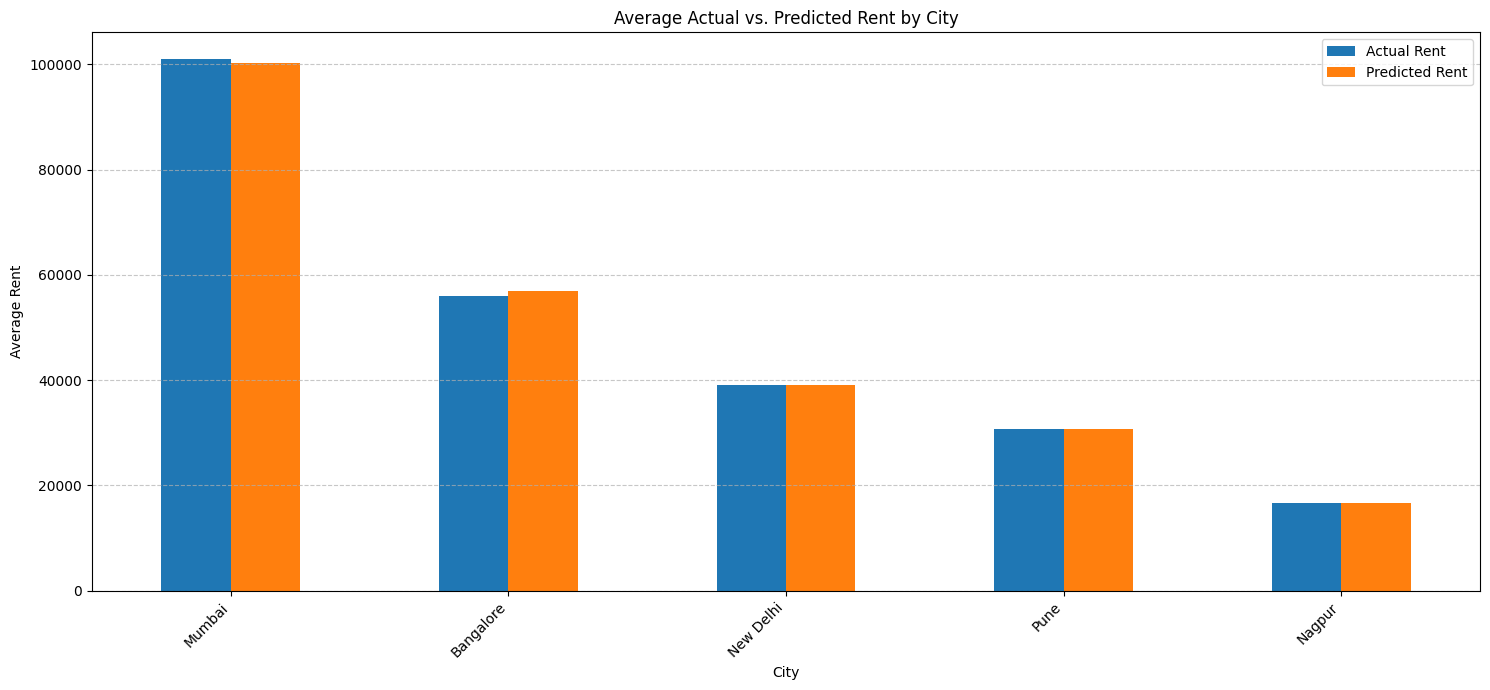

In [ ]:
#Visualize Predictions - Actual vs. Predicted Rent Trend by Area Rate and City

# Create a DataFrame to combine actual, predicted, city, and area_rate information for the test set
results_df_extended = pd.DataFrame({
    'Actual Rent': y_test,
    'Predicted Rent': y_pred,
    'city': df.loc[y_test.index, 'city'], # Get city from original df using y_test's index
    'area_rate': X_test.loc[y_test.index, 'area_rate'] # Get area_rate from X_test using y_test's index
})

# Melt the DataFrame to easily plot actual vs predicted on the same y-axis
melted_df = results_df_extended.melt(id_vars=['city', 'area_rate'],
                                     value_vars=['Actual Rent', 'Predicted Rent'],
                                     var_name='Rent Type',
                                     value_name='Rent Value')

plt.figure(figsize=(16, 9))
sns.lineplot(data=melted_df.sort_values(by=['city', 'area_rate']), # Sort for clearer lines
             x='area_rate', y='Rent Value', hue='city', style='Rent Type', markers=True, dashes=False)
plt.title('Actual vs. Predicted Rent Trend by Area Rate and City')
plt.xlabel('Area Rate')
plt.ylabel('Rent Value')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # Adjust legend position to avoid overlap
plt.tight_layout()
plt.show()